# Imports

In [16]:
from utils import *

import pandas as pd
import numpy as np
import hdbscan

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")


# Setup

In [17]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# output path for choosing components
component_output_path = [f"../results/gmm_clusters_{zone}.png" for zone in structural_zones]

# output path for interpretation
output_path = r'../results/gmm_interpretation.png'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.683097,...,0.034439,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0
1,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
2,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
3,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
4,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1


# HDBSCAN

In [6]:
# --- helper: relabel clusters by ascending mean age (noise stays -1) ---
def relabel_by_mean_age(labels, ages_1d):
    lbls = np.asarray(labels)
    ages = np.asarray(ages_1d).ravel()
    uniq = [c for c in np.unique(lbls) if c != -1]
    means = {c: ages[lbls == c].mean() for c in uniq}
    ordered = {old: new for new, old in enumerate(sorted(uniq, key=lambda c: means[c]))}
    out = lbls.copy()
    for old, new in ordered.items():
        out[lbls == old] = new
    return out

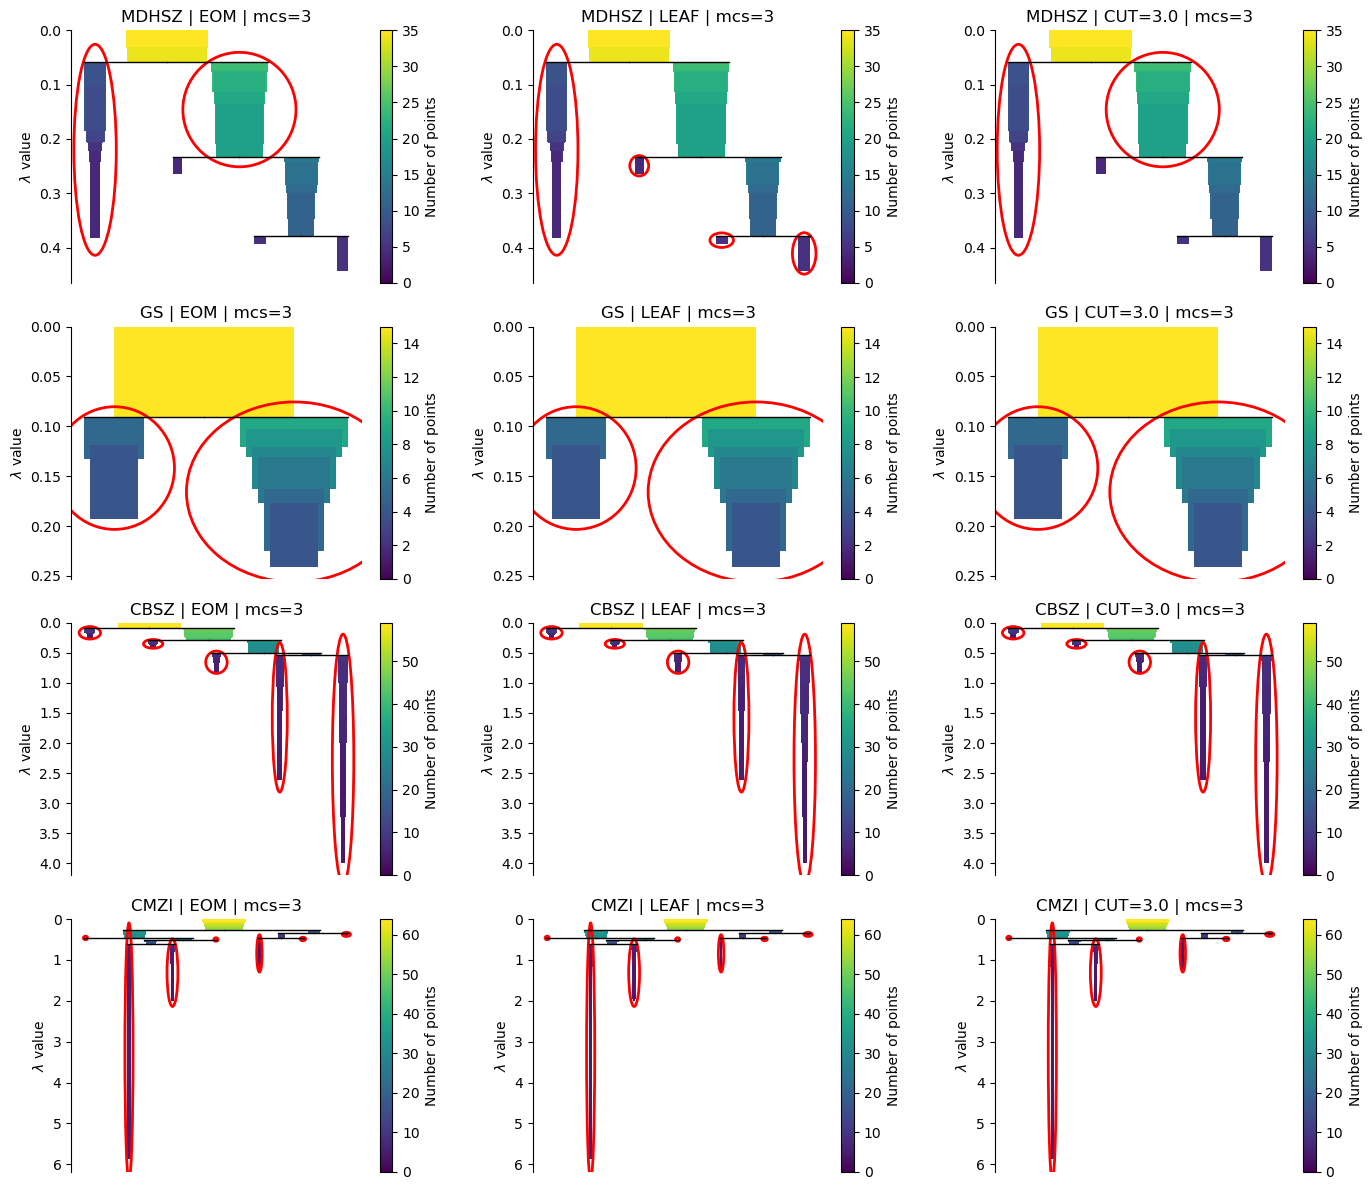

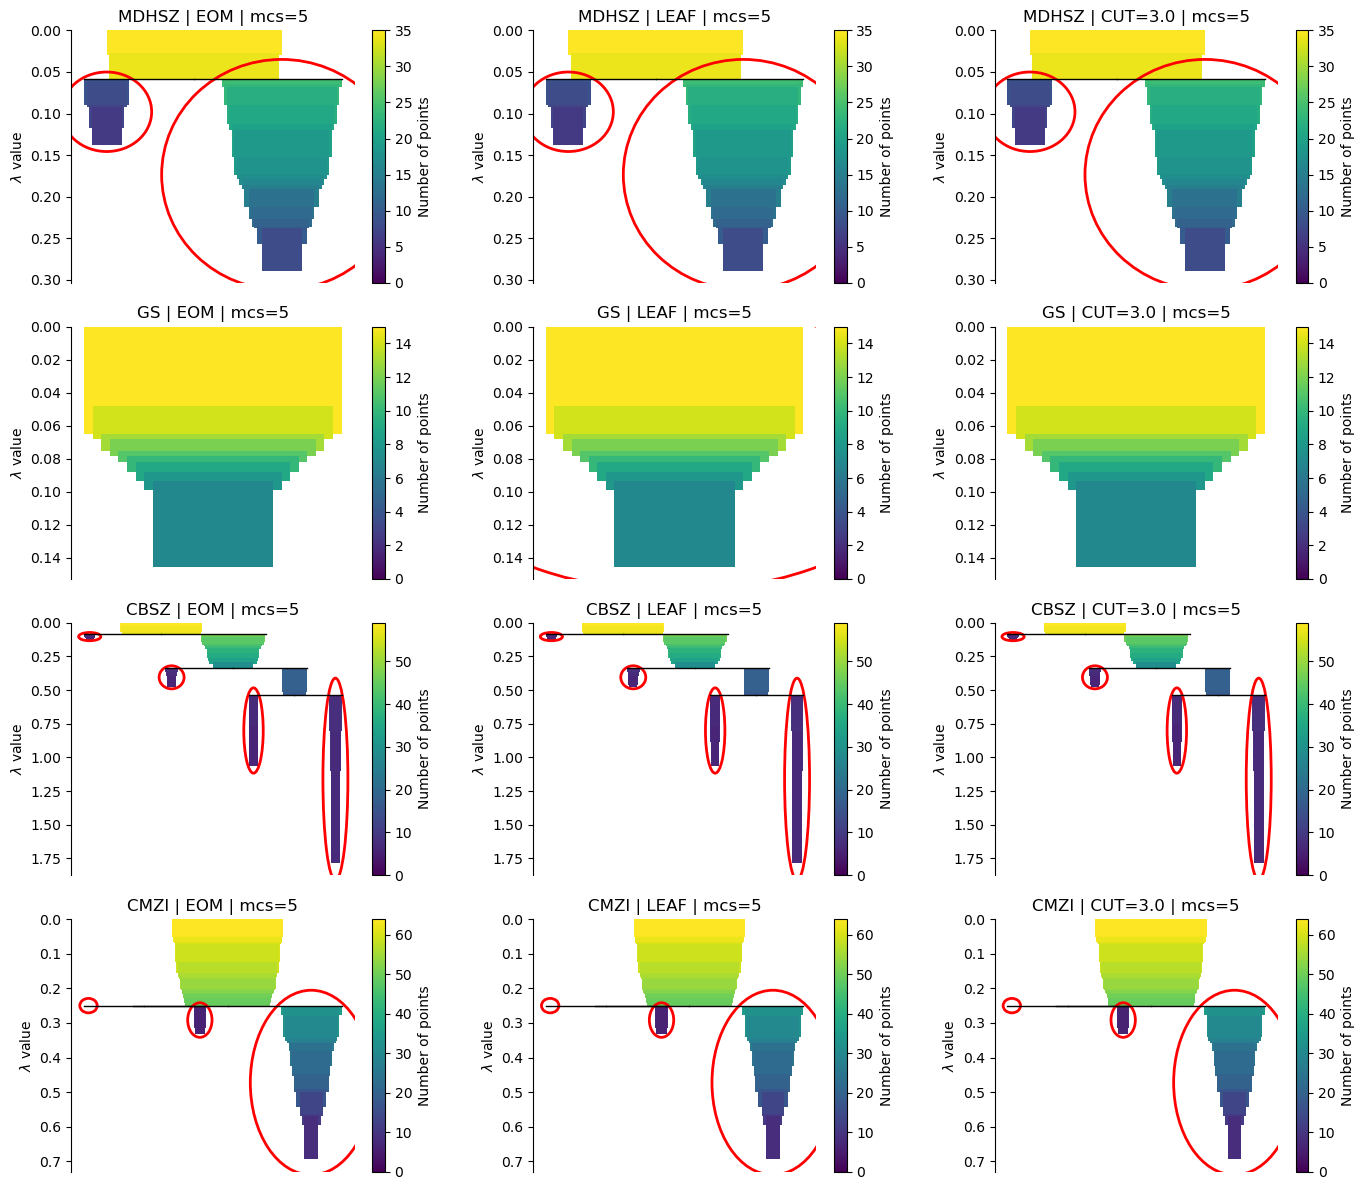

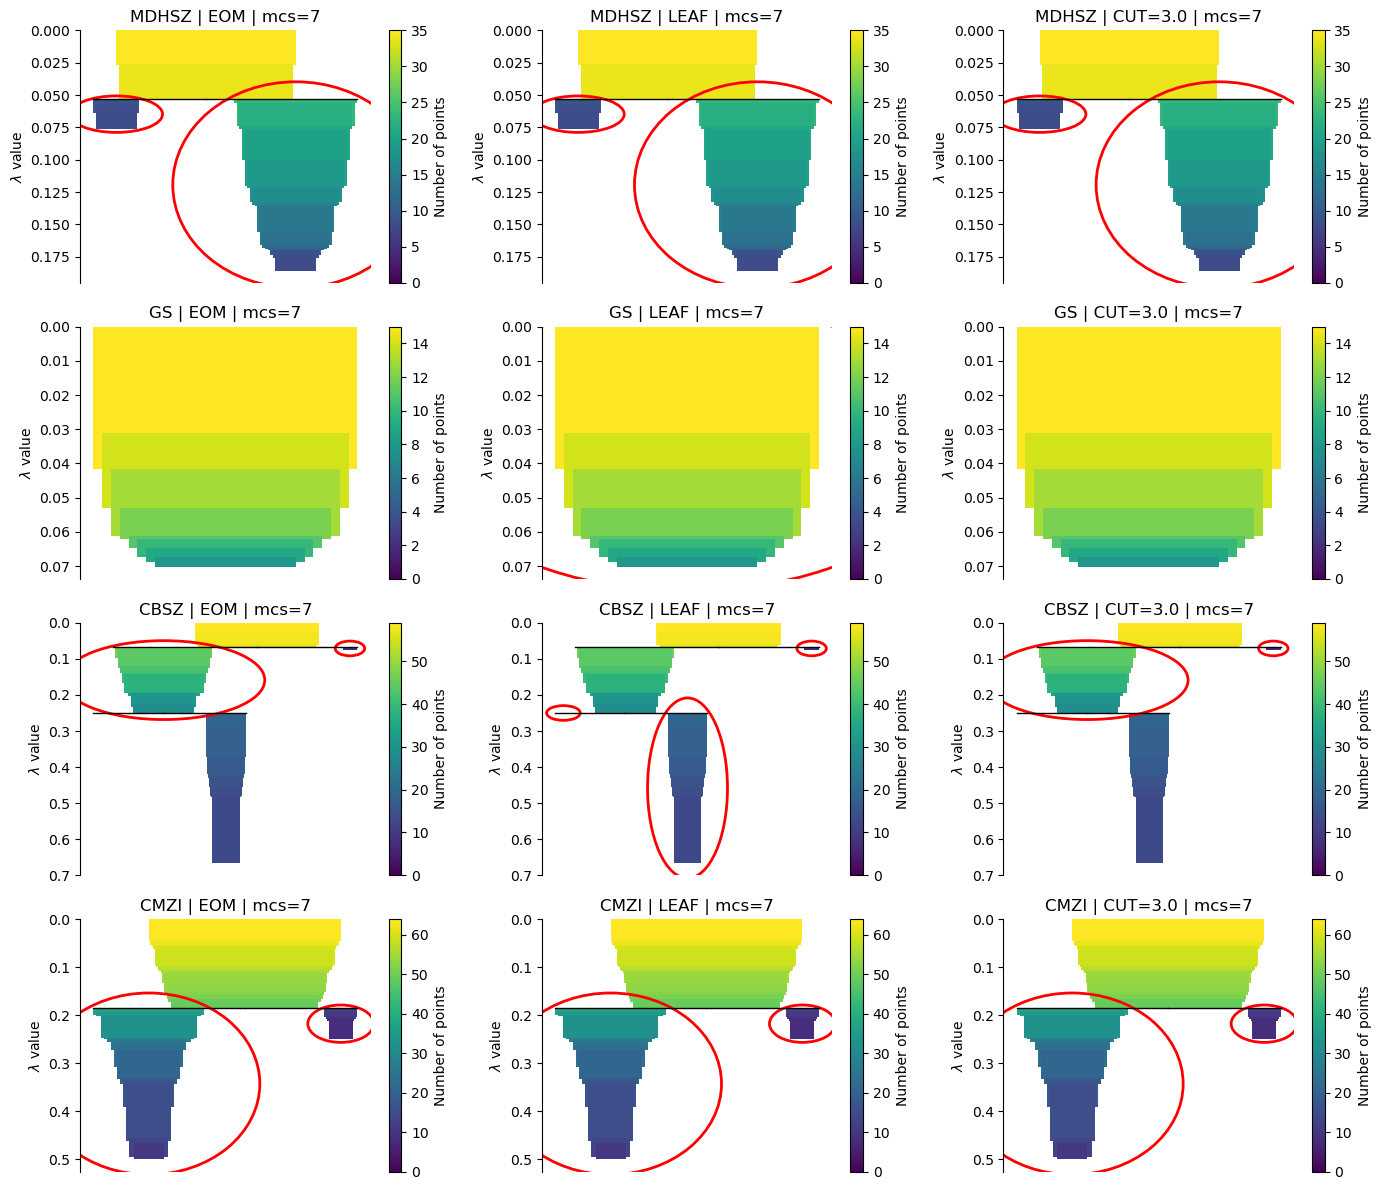

In [18]:
for min_cluster_size in [3, 5, 7]:
    min_samples = min_cluster_size

    fig, axs = plt.subplots(nrows=len(structural_zones), ncols=3, figsize=(14, 3*len(structural_zones)))
    if len(structural_zones) == 1:
        axs = np.array([axs])

    for i, zone in enumerate(structural_zones):
        df_subset = df.loc[df['zone'] == zone].copy()
        ages = df_subset['age'].to_numpy().reshape(-1, 1)

        # (A) EOM baseline
        hdb_eom = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric='euclidean',
            cluster_selection_method='eom',
            prediction_data=True
        ).fit(ages)
        df_subset['hdb_eom'] = relabel_by_mean_age(hdb_eom.labels_, ages)
        hdb_eom.condensed_tree_.plot(select_clusters=True, axis=axs[i, 0])
        axs[i, 0].set_title(f"{zone} | EOM | mcs={min_cluster_size}")

        # (B) LEAF mode (fine pulses at their natural scales)
        hdb_leaf = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric='euclidean',
            cluster_selection_method='leaf',
            prediction_data=True
        ).fit(ages)
        df_subset['hdb_leaf'] = relabel_by_mean_age(hdb_leaf.labels_, ages)
        hdb_leaf.condensed_tree_.plot(select_clusters=True, axis=axs[i, 1])
        axs[i, 1].set_title(f"{zone} | LEAF | mcs={min_cluster_size}")

        # (C) Fixed cut (DBSCAN-like): choose cut_distance yourself
        hdb_cut = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric='euclidean',
            cluster_selection_method='eom',
            prediction_data=True
        ).fit(ages)
        labels_cut = hdb_cut.dbscan_clustering(cut_distance=3.0, min_cluster_size=min_cluster_size)
        df_subset['hdb_cut'] = relabel_by_mean_age(labels_cut, ages)
        hdb_cut.condensed_tree_.plot(select_clusters=True, axis=axs[i, 2])  # no cut_distance arg here
        axs[i, 2].set_title(f"{zone} | CUT=3.0 | mcs={min_cluster_size}")

    plt.tight_layout()
    plt.show()

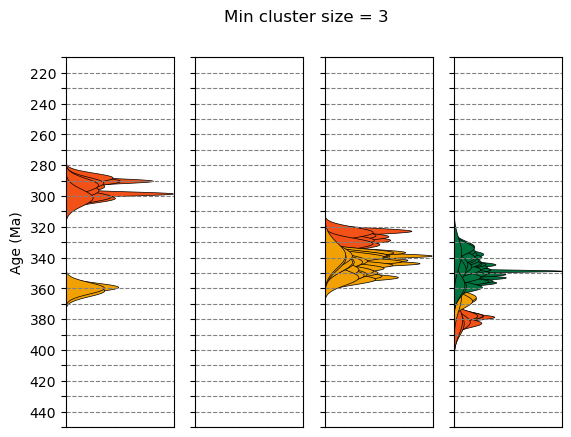

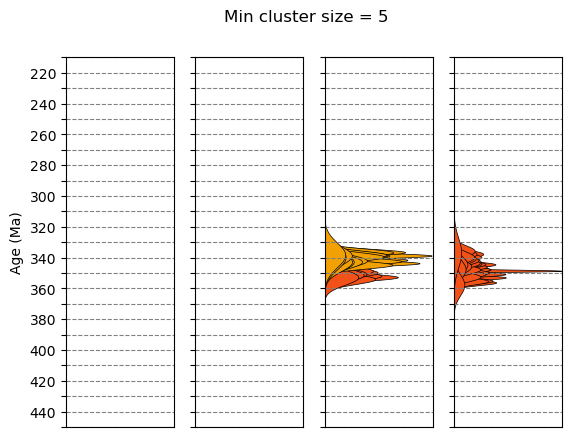

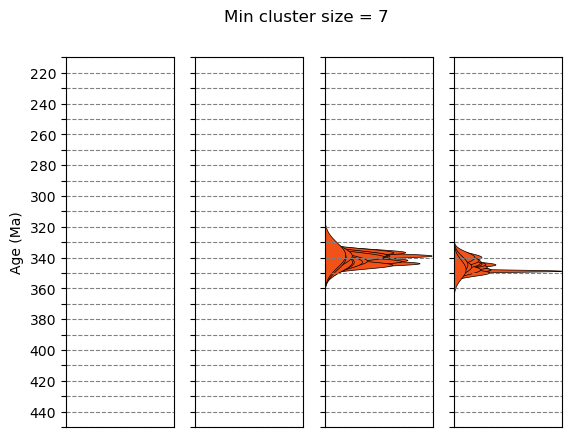

In [37]:

for min_cluster_size in [3,5,7]:

    min_samples = min_cluster_size

    fig, ax = plt.subplots(ncols=4)

    for idx, zone in enumerate(structural_zones):

        df_subset = df.loc[df['zone'] == zone].copy()
        # df_subset.sort_values('error', inplace=True)

        ages = df_subset['age'].to_numpy().reshape(-1,1)

        hdb = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples, metric='euclidean', cluster_selection_method='eom', prediction_data=False).fit(ages)

        # labels = hdb.labels_

        labels = hdb.dbscan_clustering(cut_distance=3, min_cluster_size=3)

        df_subset['labels'] = labels

        # df_subset.sort_values(['labels', 'error'], key=lambda col: col.where(col != -1, col.max() + 1), inplace=True)
        df_subset["labels_for_sort"] = df_subset["labels"].where(df_subset["labels"] != -1, 9999)
        df_subset.sort_values(["labels_for_sort", "error"], inplace=True)
        df_subset.drop(columns="labels_for_sort", inplace=True)
        df_subset.reset_index(drop=True, inplace=True)

        plot_samples_panel(df_subset.mask(df_subset['labels']==-1), ax[idx], 'labels', age_group_colors, label_bool=True, timeline=[210, 450], ylabel='Age (Ma)')

        if idx >0:
            ax[idx].set_yticklabels([])
            ax[idx].set_ylabel('')

    for a in ax:
        a.set_ylim(450,210)
    
    plt.suptitle(f"Min cluster size = {min_cluster_size}")


    plt.show()

    



In [33]:
df_subset

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite,labels
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.850,0.683097,...,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0,0
1,14,0,EB14-001,CMZI,m15,overgrowth,Y enriched overgrowth,6.0,344.750,1.756830,...,0.073922,0.029376,0.009626,0.085742,0.509595,55.893443,2.486452,1,0,0
2,24,28,WA14-002,CMZI,m14,rim,Y depleted rim,5.0,348.020,1.994397,...,0.064855,0.009446,0.011619,0.092507,0.573070,59.229705,1.779192,1,1,0
3,23,159,WA15-4,CMZI,m3,overgrowth,Y enriched overgrowth,NaN,348.000,2.006661,...,0.030578,0.096511,0.020067,0.077400,0.576627,55.085716,3.330102,0,1,0
4,25,14,EB14-002,CMZI,m18,overgrowth,Y depleted overgrowth,6.0,350.000,2.071042,...,0.088323,0.009587,0.009587,0.091671,0.591726,59.008151,1.444260,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,164,126,WA15-5,CMZI,m2,core,Y depleted core,NaN,381.000,8.611584,...,0.028705,0.073068,0.016527,0.073938,2.260258,51.178906,2.923589,0,1,-1
60,167,34,WA14-002,CMZI,m7,rim,Y depleted rim,5.0,337.080,9.649235,...,0.055397,0.008730,0.012242,0.077597,2.862595,54.905825,1.661778,1,1,-1
61,168,136,WA15-4,CMZI,m10,core,Y depeted core,NaN,365.000,9.757623,...,0.013816,0.051810,0.018997,0.069081,2.673321,50.563485,2.694140,0,1,-1
62,169,11,EB14-001,CMZI,m7,overgrowth,Y depleted overgrowth,5.0,332.820,9.896269,...,0.062135,0.008593,0.008593,0.086750,2.973460,50.347730,1.660053,1,0,-1
